# PRIM Baseline Exploration — 500 LHS runs

Find parameter boxes where:
1. T1 BCAS mortality exceeds a threshold
2. T2 NATO timeline compliance drops below a threshold

In [7]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
from ema_workbench.analysis import prim

# ── CONFIGURATION ────────────────────────────────────────────────────────────
FOLDER_NAME = "20260604_115203_scenario_1ccp_1btg_egalitarian"
T1_MORTALITY_THRESHOLD = 0.0    # mortality > this value is "interesting"
T2_TIMELINE_THRESHOLD  = 0.9    # fraction < this value is "interesting"
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(paths.MULTI_RUN_OUTPUT / FOLDER_NAME / "results.csv")
print(f"Loaded {len(df)} runs")
print(f"T1 mortality range: {df['death_rate_T1_BCAS'].min():.4f} – {df['death_rate_T1_BCAS'].max():.4f}")
print(f"T2 timeline range:  {df['frac_t2_within_timeline'].min():.4f} – {df['frac_t2_within_timeline'].max():.4f}")

# Uncertainty columns used in the experiment
UNCERTAINTIES = [c for c in ["ccp_r1_same_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"] if c in df.columns]
x = df[UNCERTAINTIES].astype(float)
print(f"Uncertainties: {UNCERTAINTIES}")

Loaded 500 runs
T1 mortality range: 0.0000 – 0.9000
T2 timeline range:  0.0000 – 1.0000
Uncertainties: ['ccp_r1_same_bn_min', 'bcas_rate', 'waves_per_day', 'wave_duration_min']


## 1. PRIM — T1 BCAS Mortality

Cases of interest: 207 / 500 (41.4%)

Selected box (click on tradeoff plot to change):
coverage     0.391304
density      0.941860
id          24.000000
k           81.000000
mass         0.172000
mean         0.941860
n           86.000000
res_dim      4.000000
Name: 24, dtype: float64

                       box 24                                    
                          min         max      qp value  qp value
waves_per_day        1.000000    5.500000           NaN  0.276767
ccp_r1_same_bn_min  20.500000   29.500000  2.260305e-21  0.517533
bcas_rate            0.021027    0.079844  2.352783e-04       NaN
wave_duration_min   10.500000  104.500000  1.722403e-01  0.029873


[None]

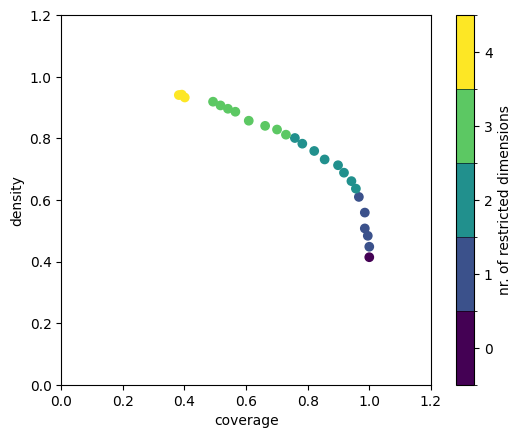

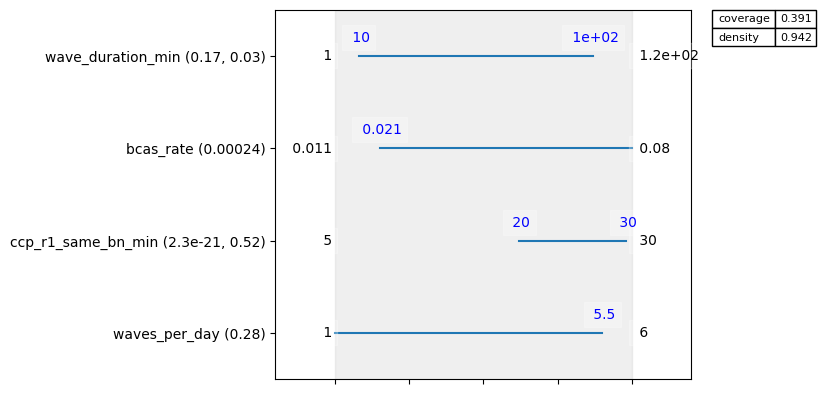

In [8]:
y_t1 = df["death_rate_T1_BCAS"].values > T1_MORTALITY_THRESHOLD
print(f"Cases of interest: {y_t1.sum()} / {len(y_t1)} ({y_t1.mean():.1%})")

p_t1 = prim.Prim(x, y_t1, threshold=0.5)
box_t1 = p_t1.find_box()
box_t1.show_tradeoff()
print("\nSelected box (click on tradeoff plot to change):")
box_t1.inspect(style="graph")
box_t1.inspect()

## 2. PRIM — T2 NATO Timeline Compliance

Cases of interest: 404 / 500 (80.8%)

Selected box (click on tradeoff plot to change):
coverage      0.579208
density       1.000000
id           11.000000
k           234.000000
mass          0.468000
mean          1.000000
n           234.000000
res_dim       2.000000
Name: 11, dtype: float64

                       box 11                                  
                          min        max      qp value qp value
ccp_r1_same_bn_min  15.500000  30.000000  1.189435e-15      NaN
bcas_rate            0.022541   0.079844  2.562360e-04      NaN


[None]

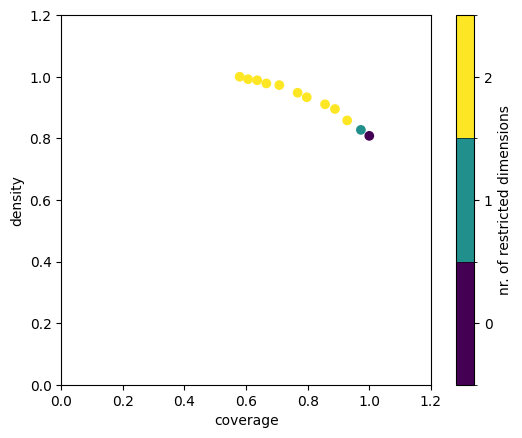

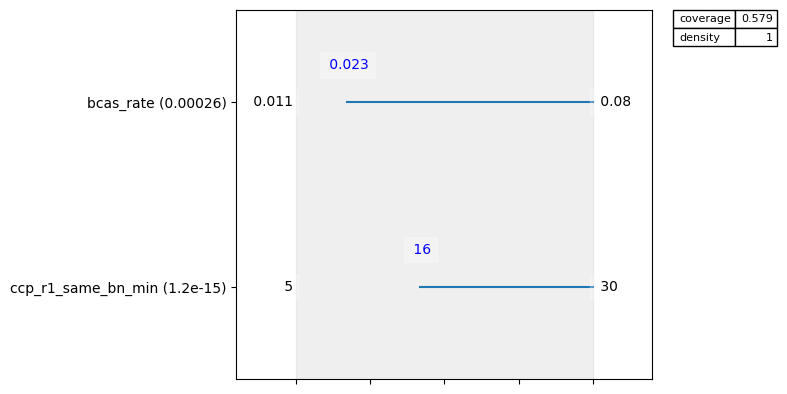

In [9]:
y_t2 = df["frac_t2_within_timeline"].values < T2_TIMELINE_THRESHOLD
print(f"Cases of interest: {y_t2.sum()} / {len(y_t2)} ({y_t2.mean():.1%})")

p_t2 = prim.Prim(x, y_t2, threshold=0.5)
box_t2 = p_t2.find_box()
box_t2.show_tradeoff()
print("\nSelected box (click on tradeoff plot to change):")
box_t2.inspect(style="graph")
box_t2.inspect()